# Experiment: Support Vector Machine (SVM)



**Aim:** To implement Linear, RBF and Polynomial SVM, visualize support vectors and decision boundaries, and try different C and gamma values.

**Library:** Scikit-learn and Matplotlib

## 1. Import libraries and create dataset

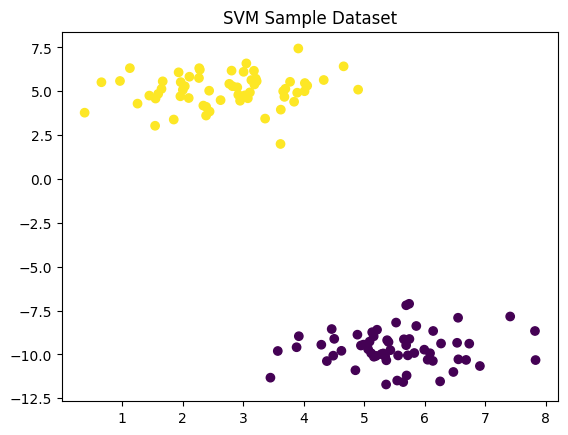

In [ ]:
## 1. Import libraries and create dataset

import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create simple dataset
X, y = make_blobs(n_samples=120, centers=2, random_state=10)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("SVM Sample Dataset")
plt.show()

## 2. Train three SVM models

In [ ]:
## 2. Train three SVM models

# Linear SVM
linear = SVC(kernel="linear", C=2)
linear.fit(X_train, y_train)

# RBF SVM
rbf = SVC(kernel="rbf", C=2, gamma=0.5)
rbf.fit(X_train, y_train)

# Polynomial SVM
poly = SVC(kernel="poly", degree=4, C=2)
poly.fit(X_train, y_train)

print("Linear Accuracy:", accuracy_score(y_test, linear.predict(X_test)))
print("RBF Accuracy:", accuracy_score(y_test, rbf.predict(X_test)))
print("Polynomial Accuracy:", accuracy_score(y_test, poly.predict(X_test)))

Linear Accuracy: 1.0
RBF Accuracy: 1.0
Polynomial Accuracy: 1.0


## 3. Visualize decision boundary and support vectors

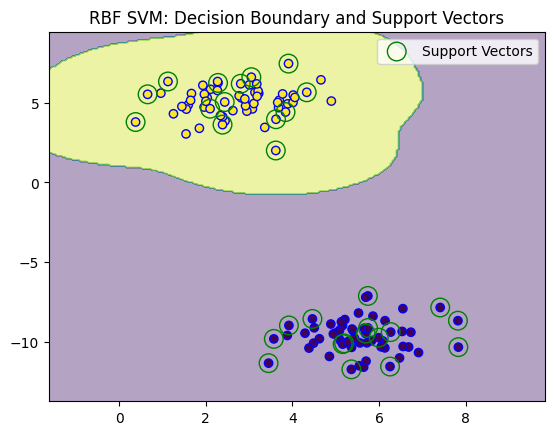

In [ ]:
## 3. Visualize decision boundary and support vectors

# Select a model to visualize
model = rbf

# Make a grid for plotting
import numpy as np

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-2, X[:, 0].max()+2, 250),
    np.linspace(X[:, 1].min()-2, X[:, 1].max()+2, 250)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.4)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="blue")

plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=180,
    facecolors="none",
    edgecolors="green",
    label="Support Vectors"
)

# Show margin lines for linear SVM
if model.kernel == "linear":
    decision = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    decision = decision.reshape(xx.shape)

    plt.contour(
        xx, yy, decision,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )

plt.title("RBF SVM: Decision Boundary and Support Vectors")
plt.legend()
plt.show()

**Try another kernel:** In the visualization cell, change `model = linear` to `model = rbf` or `model = poly` and run the cell again. The red circles show support vectors. Margin lines are drawn for the linear SVM.

## 4. Try different C and gamma values

In [ ]:
## 4. Try different C and gamma values

# Try different C values
for c in [0.5, 2, 20]:
    model = SVC(kernel="rbf", C=c, gamma=0.5)
    model.fit(X_train, y_train)

    print("C =", c, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

# Try different gamma values
for g in [0.5, 2, 5]:
    model = SVC(kernel="rbf", C=2, gamma=g)
    model.fit(X_train, y_train)

    print("Gamma =", g, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

C = 0.5 Accuracy = 1.0
C = 2 Accuracy = 1.0
C = 20 Accuracy = 1.0
Gamma = 0.5 Accuracy = 1.0
Gamma = 2 Accuracy = 1.0
Gamma = 5 Accuracy = 0.9


## Observations
1. SVM separates data into different classes.
2. Linear SVM uses a straight decision boundary.
3. RBF and Polynomial kernels can form curved decision boundaries.
4. Support vectors are the important data points near the boundary.
5. C and gamma values can change the model accuracy.

## Result
Linear, RBF and Polynomial SVM models were trained. Their accuracy was compared, support vectors and decision boundaries were visualized, and different C and gamma values were tested.